# Problem 1: Smart Home Energy Consumption Analysis using Bayesian Networks

**AI (CSL304) - Group Assignment 2**

**Group: Edipy**

| Name | Roll No |
|---|---|
| Sarthak Shrivastava | B24CS506 |
| Potnuru Jagath | B24CS034 |
| Vidit Shrimali | B24DS038 |
| Prashant Sati | B24CS035 |
| Kamalesh Swargam | B24MT011 |

The network structure, the CPTs from the assignment and a few small helpers are
kept in `bn.py` so that this notebook stays readable. Parts A to E follow in order.

Run top to bottom; needs `pgmpy`, `networkx`, `pandas`, `matplotlib`.

## Part A: Expert Bayesian Network

### A1. Building the network

In [1]:
import warnings
warnings.filterwarnings("ignore")

from itertools import product

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE

from bn import (CPT, EDGES, LABELS, ORDER, PARENTS, QUERIES, STATES,
                build_expert_model, cpd_frame, prob, run_queries)

model = build_expert_model()
print("Nodes:", model.nodes())
print("Edges:", model.edges())
print("check_model:", model.check_model())

Nodes: ['DayType', 'Occupancy', 'Weather', 'AC', 'Load', 'Energy']
Edges: [('DayType', 'Occupancy'), ('Occupancy', 'AC'), ('Occupancy', 'Load'), ('Weather', 'AC'), ('AC', 'Energy'), ('Load', 'Energy')]
check_model: True


### A2. The CPTs, and the sum-to-1 check

Each column of a CPT is one parent configuration, so a valid CPT has every
column summing to 1.

In [2]:
for cpd in model.get_cpds():
    display(cpd_frame(cpd))

,P
Weather,
Hot,0.5
Mild,0.3
Cold,0.2


,P
DayType,
Weekday,0.7
Weekend,0.3


DayType,Weekday,Weekend
Occupancy,,
High,0.45,0.8
Low,0.55,0.2


"Weather, Occupancy","Hot, High","Hot, Low","Mild, High","Mild, Low","Cold, High","Cold, Low"
AC,,,,,,
On,0.9,0.6,0.4,0.15,0.1,0.05
Off,0.1,0.4,0.6,0.85,0.9,0.95


Occupancy,High,Low
Load,,
Heavy,0.75,0.35
Light,0.25,0.65


"AC, Load","On, Heavy","On, Light","Off, Heavy","Off, Light"
Energy,,,,
High,0.92,0.68,0.55,0.12
Low,0.08,0.32,0.45,0.88


In [3]:
all_ok = True
for cpd in model.get_cpds():
    col_sums = cpd.get_values().sum(axis=0)
    ok = np.allclose(col_sums, 1.0)
    all_ok = all_ok and ok
    print(f"{cpd.variable:10s} parent configs: {len(col_sums):2d}"
          f"  column sums: {np.round(col_sums, 6)}  -> {'OK' if ok else 'FAIL'}")

print("\nEvery CPT sums to 1 for every parent configuration:", all_ok)

Weather    parent configs:  1  column sums: [1.]  -> OK
DayType    parent configs:  1  column sums: [1.]  -> OK
Occupancy  parent configs:  2  column sums: [1. 1.]  -> OK
AC         parent configs:  6  column sums: [1. 1. 1. 1. 1. 1.]  -> OK
Load       parent configs:  2  column sums: [1. 1.]  -> OK
Energy     parent configs:  4  column sums: [1. 1. 1. 1.]  -> OK

Every CPT sums to 1 for every parent configuration: True


### A3. Visualising the network

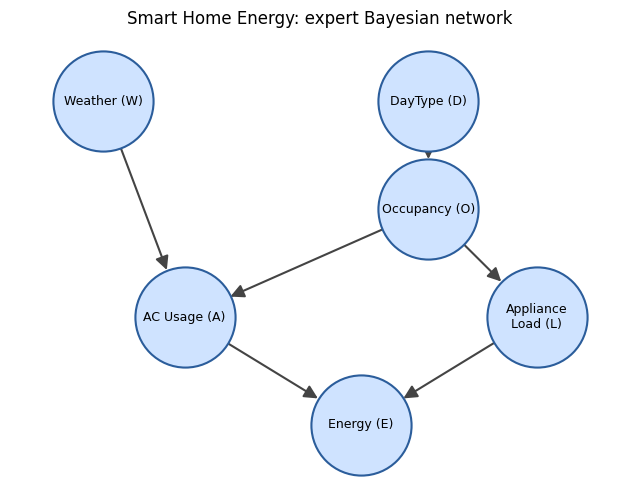

In [4]:
pos = {"Weather": (0, 3), "DayType": (2.4, 3), "Occupancy": (2.4, 2),
       "AC": (0.6, 1), "Load": (3.2, 1), "Energy": (1.9, 0)}
labels = {"Weather": "Weather (W)", "DayType": "DayType (D)",
          "Occupancy": "Occupancy (O)", "AC": "AC Usage (A)",
          "Load": "Appliance\nLoad (L)", "Energy": "Energy (E)"}

plt.figure(figsize=(8, 6))
graph = nx.DiGraph(EDGES)
nx.draw_networkx_nodes(graph, pos, node_size=5200, node_color="#cfe3ff",
                       edgecolors="#2b5d9b", linewidths=1.5)
nx.draw_networkx_labels(graph, pos, labels, font_size=9)
nx.draw_networkx_edges(graph, pos, node_size=5200, arrowsize=20,
                       width=1.5, edge_color="#444")
plt.title("Smart Home Energy: expert Bayesian network")
plt.axis("off")
plt.margins(0.15)
plt.savefig("network.png", dpi=150, bbox_inches="tight")
plt.show()

### A4. Queries Q1 to Q7 by variable elimination

In [5]:
expert = run_queries(model)

results = pd.DataFrame(
    {"Query": [LABELS[q] for q in LABELS],
     "Probability": [round(expert[q], 4) for q in LABELS]},
    index=list(LABELS))
results

,Query,Probability
Q1,P(E=High),0.5806
Q2,P(E=High | W=Hot),0.7063
Q3,P(E=High | D=Weekend),0.6402
Q4,"P(E=High | W=Cold, O=High)",0.4843
Q5,P(W=Hot | E=High),0.6082
Q6,P(AC=On | E=High),0.6929
Q7,"P(AC=On | E=High, L=Heavy)",0.6499


Cross-check: the same seven numbers by plain enumeration over the full joint,
straight from the CPT dictionaries without pgmpy. This also confirms the CPD
columns were filled in the right order.

In [6]:
def joint(cpt, assignment):
    """P(assignment) using the factorisation implied by PARENTS."""
    p = 1.0
    for var in ORDER:
        p *= cpt[var][tuple(assignment[par] for par in PARENTS[var])][assignment[var]]
    return p


def enum_query(cpt, var, state, evidence):
    """P(var = state | evidence) by summing the joint over everything else."""
    numerator = denominator = 0.0
    for values in product(*[STATES[v] for v in ORDER]):
        assignment = dict(zip(ORDER, values))
        if any(assignment[k] != v for k, v in evidence.items()):
            continue
        p = joint(cpt, assignment)
        denominator += p
        if assignment[var] == state:
            numerator += p
    return numerator / denominator


for q, args in QUERIES.items():
    by_enum = enum_query(CPT, *args)
    print(f"{q}: elimination = {expert[q]:.6f}   enumeration = {by_enum:.6f}"
          f"   match = {abs(by_enum - expert[q]) < 1e-9}")

Q1: elimination = 0.580631   enumeration = 0.580631   match = True
Q2: elimination = 0.706266   enumeration = 0.706266   match = True
Q3: elimination = 0.640199   enumeration = 0.640199   match = True
Q4: elimination = 0.484250   enumeration = 0.484250   match = True
Q5: elimination = 0.608188   enumeration = 0.608188   match = True
Q6: elimination = 0.692867   enumeration = 0.692867   match = True
Q7: elimination = 0.649899   enumeration = 0.649899   match = True


### A5. Explaining away (Q6 against Q7)

Q6 = 0.6929 and Q7 = 0.6499, so adding L=Heavy *lowers* P(AC=On) by 0.043.

AC and Load are both parents of Energy, so A -> E <- L is a v-structure. Seeing
E=High pushes P(AC=On) up from its prior 0.4854 to 0.6929, because the AC is one
of the two likely causes. Being told the load was heavy then supplies the other
cause: P(E=High | Off, Heavy) = 0.55 against only 0.12 for Off, Light. The AC is
needed less to account for the high reading, so its probability falls. That is
explaining away.

It does not drop all the way back to 0.4854 because a heavy load also makes
O=High more likely, and high occupancy makes AC=On more likely. That pushes the
other way, just not as hard.

In [7]:
infer = VariableElimination(model)

print("P(AC=On)                        =", round(prob(infer, "AC", "On", {}), 4))
print("P(AC=On | L=Heavy)              =", round(prob(infer, "AC", "On", {"Load": "Heavy"}), 4))
print("P(AC=On | E=High)          (Q6) =", round(expert["Q6"], 4))
print("P(AC=On | E=High, L=Heavy) (Q7) =", round(expert["Q7"], 4))
print("\nQ6 - Q7 =", round(expert["Q6"] - expert["Q7"], 4))

P(AC=On)                        = 0.4854
P(AC=On | L=Heavy)              = 0.526
P(AC=On | E=High)          (Q6) = 0.6929
P(AC=On | E=High, L=Heavy) (Q7) = 0.6499

Q6 - Q7 = 0.043


### A6. Q1 by hand

By the factorisation of the network,

```
P(E=High) = sum_w sum_d sum_o sum_a sum_l P(w) P(d) P(o|d) P(a|w,o) P(l|o) P(E=High|a,l)
```

The sums for w and d can be pushed inward, because Weather only enters through
P(a|w,o) and DayType only through P(o|d):

```
P(E=High) = sum_o P(o) * sum_a sum_l P(a|o) P(l|o) P(E=High|a,l)

where   P(o)   = sum_d P(d) P(o|d)
        P(a|o) = sum_w P(w) P(a|w,o)
```

**Step 1: P(O)**

P(O=High) = 0.7 * 0.45 + 0.3 * 0.80 = 0.315 + 0.240 = **0.555**, so P(O=Low) = **0.445**

**Step 2: P(A=On | O)**

P(A=On | O=High) = 0.5 * 0.90 + 0.3 * 0.40 + 0.2 * 0.10 = 0.45 + 0.12 + 0.02 = **0.59**

P(A=On | O=Low) = 0.5 * 0.60 + 0.3 * 0.15 + 0.2 * 0.05 = 0.30 + 0.045 + 0.01 = **0.355**

**Step 3: P(E=High | O)**, summing over A and L, which are independent given O

For O=High, using P(A=On)=0.59 and P(L=Heavy)=0.75:

| A | L | P(a\|O) * P(l\|O) * P(E=High\|a,l) | value |
|---|---|---|---|
| On | Heavy | 0.59 * 0.75 * 0.92 | 0.407100 |
| On | Light | 0.59 * 0.25 * 0.68 | 0.100300 |
| Off | Heavy | 0.41 * 0.75 * 0.55 | 0.169125 |
| Off | Light | 0.41 * 0.25 * 0.12 | 0.012300 |
| | | **total** | **0.688825** |

For O=Low, using P(A=On)=0.355 and P(L=Heavy)=0.35:

| A | L | P(a\|O) * P(l\|O) * P(E=High\|a,l) | value |
|---|---|---|---|
| On | Heavy | 0.355 * 0.35 * 0.92 | 0.114310 |
| On | Light | 0.355 * 0.65 * 0.68 | 0.156910 |
| Off | Heavy | 0.645 * 0.35 * 0.55 | 0.124163 |
| Off | Light | 0.645 * 0.65 * 0.12 | 0.050310 |
| | | **total** | **0.445693** |

**Step 4: combine**

P(E=High) = 0.555 * 0.688825 + 0.445 * 0.445693 = 0.382298 + 0.198333 = **0.580631**

which is the Q1 value produced by the code.

In [8]:
# the same four steps, in code, to confirm the hand calculation
p_occ = {"High": 0.7 * 0.45 + 0.3 * 0.80}
p_occ["Low"] = 1 - p_occ["High"]

p_ac_on = {o: sum(CPT["Weather"][()][w] * CPT["AC"][(w, o)]["On"]
                  for w in STATES["Weather"])
           for o in STATES["Occupancy"]}

p_energy_high = {}
for o in STATES["Occupancy"]:
    total = 0.0
    for a in STATES["AC"]:
        for l in STATES["Load"]:
            p_a = p_ac_on[o] if a == "On" else 1 - p_ac_on[o]
            p_l = CPT["Load"][(o,)][l]
            total += p_a * p_l * CPT["Energy"][(a, l)]["High"]
    p_energy_high[o] = total

by_hand = sum(p_occ[o] * p_energy_high[o] for o in STATES["Occupancy"])

print("P(O)           =", {o: round(v, 6) for o, v in p_occ.items()})
print("P(A=On | O)    =", {o: round(v, 6) for o, v in p_ac_on.items()})
print("P(E=High | O)  =", {o: round(v, 6) for o, v in p_energy_high.items()})
print(f"\nby hand  Q1 = {by_hand:.6f}")
print(f"pgmpy    Q1 = {expert['Q1']:.6f}")
print("match:", abs(by_hand - expert["Q1"]) < 1e-9)

P(O)           = {'High': 0.555, 'Low': 0.445}
P(A=On | O)    = {'High': 0.59, 'Low': 0.355}
P(E=High | O)  = {'High': 0.688825, 'Low': 0.445693}

by hand  Q1 = 0.580631
pgmpy    Q1 = 0.580631
match: True


## Part B: Conditional Independence Analysis

A path is blocked if it contains a chain (-> X ->) or a fork (<- X ->) whose
middle node X is observed, or a collider (-> X <-) where neither X nor any
descendant of X is observed. Two variables are d-separated if every path between
them is blocked.

### B1. Weather ⊥ DayType: holds

Two paths join W and D:

1. `W -> A <- O <- D`: A is a collider, and neither A nor its descendant E is
   observed, so the path is blocked.
2. `W -> A -> E <- L <- O <- D`: here A is a chain node and the collider is E,
   which is unobserved and has no descendants, so this path is blocked too.

Both are blocked, so the statement holds.

### B2. Weather ⊥ DayType | Energy: does not hold

On the first path, observing E activates the collider at A, since E is a
descendant of A. O is still unobserved, so the rest of the path stays open. The
path is active and W and D become dependent.

In words: on a high-consumption day, learning it was a weekend explains part of
the usage, which changes how likely hot weather was.

### B3. Weather ⊥ ApplianceLoad | Occupancy: holds

1. `W -> A <- O -> L`: A is an unobserved collider with E unobserved as well,
   and observing O blocks the fork a second time.
2. `W -> A -> E <- L`: E is an unobserved collider with no descendants.

Both are blocked, so the statement holds.

In [9]:
print("pgmpy d-connection checks (False means d-separated)")
print("  W, D      :", model.is_dconnected("Weather", "DayType"))
print("  W, D | E  :", model.is_dconnected("Weather", "DayType", observed=["Energy"]))
print("  W, L | O  :", model.is_dconnected("Weather", "Load", observed=["Occupancy"]))

pgmpy d-connection checks (False means d-separated)
  W, D      : False
  W, D | E  : True
  W, L | O  : False


Numerical check: compare the distribution of Weather with and without the extra
variable in the evidence. If the statement holds, the columns match exactly.

In [10]:
def compare(evidence, extra, title):
    rows = []
    for w in STATES["Weather"]:
        row = {"Weather": w, "P(W | evidence)": prob(infer, "Weather", w, evidence)}
        for state in STATES[extra]:
            key = f"P(W | evidence, {extra}={state})"
            row[key] = prob(infer, "Weather", w, {**evidence, extra: state})
        rows.append(row)

    frame = pd.DataFrame(rows).set_index("Weather").round(4)
    spread = frame.sub(frame.iloc[:, 0], axis=0).abs().values.max()
    print(f"{title}:  max |difference| = {spread:.6f}")
    return frame


compare({}, "DayType", "B1, W against D")

B1, W against D:  max |difference| = 0.000000


,P(W | evidence),"P(W | evidence, DayType=Weekday)","P(W | evidence, DayType=Weekend)"
Weather,,,
Hot,0.5,0.5,0.5
Mild,0.3,0.3,0.3
Cold,0.2,0.2,0.2


In [11]:
compare({"Energy": "High"}, "DayType", "B2, W against D given E=High")

B2, W against D given E=High:  max |difference| = 0.008400


,P(W | evidence),"P(W | evidence, DayType=Weekday)","P(W | evidence, DayType=Weekend)"
Weather,,,
Hot,0.6082,0.6124,0.5998
Mild,0.2540,0.2506,0.2608
Cold,0.1378,0.1370,0.1395


In [12]:
compare({"Energy": "Low"}, "DayType", "B2, W against D given E=Low")

B2, W against D given E=Low:  max |difference| = 0.027700


,P(W | evidence),"P(W | evidence, DayType=Weekday)","P(W | evidence, DayType=Weekend)"
Weather,,,
Hot,0.3502,0.3598,0.3225
Mild,0.3637,0.3616,0.3698
Cold,0.2861,0.2786,0.3077


In [13]:
b3 = {o: compare({"Occupancy": o}, "Load", f"B3, W against L given O={o}")
      for o in STATES["Occupancy"]}
pd.concat(b3, names=["Occupancy"])

B3, W against L given O=High:  max |difference| = 0.000000
B3, W against L given O=Low:  max |difference| = 0.000000


P(W | evidence)  P(W | evidence, Load=Heavy)  \
Occupancy Weather                                                 
High      Hot                  0.5                          0.5   
          Mild                 0.3                          0.3   
          Cold                 0.2                          0.2   
Low       Hot                  0.5                          0.5   
          Mild                 0.3                          0.3   
          Cold                 0.2                          0.2   

                   P(W | evidence, Load=Light)  
Occupancy Weather                               
High      Hot                              0.5  
          Mild                             0.3  
          Cold                             0.2  
Low       Hot                              0.5  
          Mild                             0.3  
          Cold                             0.2

**Summary of Part B**

| Statement | d-separation | Numerically |
|---|---|---|
| W ⊥ D | holds | P(W) unchanged by D, difference 0 |
| W ⊥ D given E | fails | P(W=Hot \| E=High) = 0.6082, against 0.5998 Weekend and 0.6124 Weekday |
| W ⊥ L given O | holds | P(W \| O) unchanged by L, difference 0 |

The B2 dependence is small, 0.0084 given E=High and 0.0277 given E=Low, because the
route from D to W is long and each link shifts things only slightly. It is still nonzero, which is what decides
independence.

## Part C: Synthetic Data Generation

Ancestral sampling, written out rather than taken from a library: nodes are
visited in topological order, and each value is drawn from the CPT row picked out
by the parents already sampled. One fixed seed per size, reported below.

In [14]:
SIZES = [500, 5000, 20000]
SEEDS = {500: 42, 5000: 56, 20000: 67}


def sample_one(rng):
    """One full assignment, sampling each node after its parents."""
    row = {}
    for var in ORDER:
        dist = CPT[var][tuple(row[par] for par in PARENTS[var])]
        u, cumulative = rng.random(), 0.0
        for state in STATES[var]:
            cumulative += dist[state]
            if u < cumulative:
                break
        row[var] = state
    return row


def generate(n, seed):
    rng = np.random.default_rng(seed)
    return pd.DataFrame([sample_one(rng) for _ in range(n)], columns=ORDER)


data = {n: generate(n, SEEDS[n]) for n in SIZES}

print("seeds:", SEEDS)
print("shapes:", {n: d.shape for n, d in data.items()})
data[500].head()

seeds: {500: 42, 5000: 56, 20000: 67}
shapes: {500: (500, 6), 5000: (5000, 6), 20000: (20000, 6)}


,Weather,DayType,Occupancy,AC,Load,Energy
0,Mild,Weekday,Low,Off,Heavy,Low
1,Mild,Weekend,High,Off,Heavy,Low
2,Mild,Weekend,High,On,Heavy,High
3,Cold,Weekday,Low,Off,Light,Low
4,Mild,Weekday,Low,On,Heavy,High


In [15]:
for n in SIZES:
    d = data[n]
    print(f"=== n = {n}, seed = {SEEDS[n]} ===")

    freq = d["Weather"].value_counts(normalize=True).reindex(STATES["Weather"])
    true = pd.Series({w: CPT["Weather"][()][w] for w in STATES["Weather"]})
    print("Weather empirical frequency against the true prior")
    print(pd.DataFrame({"empirical": freq.round(4), "true": true}).to_string())

    print("\n(Weather, Occupancy) counts")
    print(pd.crosstab(d["Weather"], d["Occupancy"])
            .reindex(index=STATES["Weather"], columns=STATES["Occupancy"]).to_string())
    print()

=== n = 500, seed = 42 ===
Weather empirical frequency against the true prior
      empirical  true
Hot       0.510   0.5
Mild      0.286   0.3
Cold      0.204   0.2

(Weather, Occupancy) counts
Occupancy  High  Low
Weather             
Hot         155  100
Mild         75   68
Cold         51   51

=== n = 5000, seed = 56 ===
Weather empirical frequency against the true prior
      empirical  true
Hot      0.5034   0.5
Mild     0.2988   0.3
Cold     0.1978   0.2

(Weather, Occupancy) counts
Occupancy  High   Low
Weather              
Hot        1387  1130
Mild        811   683
Cold        546   443

=== n = 20000, seed = 67 ===
Weather empirical frequency against the true prior
      empirical  true
Hot      0.4962   0.5
Mild     0.3033   0.3
Cold     0.2006   0.2

(Weather, Occupancy) counts
Occupancy  High   Low
Weather              
Hot        5539  4384
Mild       3337  2729
Cold       2275  1736



## Part D: Learning from Data

### D1 and D2. Fitting both estimators on the expert structure

Both estimators are fitted on the same structure as the expert network, so only the
parameters differ. `state_names` is passed so the learned CPTs keep the full state
space regardless of what a given sample happens to contain.

In [16]:
ESTIMATORS = {
    "MLE": lambda: DiscreteMLE(state_names=STATES),
    "Bayesian": lambda: DiscreteBayesianEstimator(
        state_names=STATES, prior_type="BDeu", equivalent_sample_size=10),
}


def learn(d, kind):
    learned = DiscreteBayesianNetwork(EDGES)
    learned.fit(d, estimator=ESTIMATORS[kind]())
    return learned


models, learned_results = {}, {}
for n in SIZES:
    for kind in ESTIMATORS:
        learned = learn(data[n], kind)
        models[n, kind] = learned
        learned_results[n, kind] = run_queries(learned)
        print(f"n = {n:5d}  {kind:8s}  check_model = {learned.check_model()}")

n =   500  MLE       check_model = True
n =   500  Bayesian  check_model = True
n =  5000  MLE       check_model = True


n =  5000  Bayesian  check_model = True
n = 20000  MLE       check_model = True


n = 20000  Bayesian  check_model = True


### D3. The learned AC Usage CPT next to the expert CPT

In [17]:
expert_ac = cpd_frame(model.get_cpds("AC"))

for n in SIZES:
    side_by_side = pd.concat(
        {"Expert": expert_ac,
         "MLE": cpd_frame(models[n, "MLE"].get_cpds("AC")),
         "Bayesian (BDeu, ESS=10)": cpd_frame(models[n, "Bayesian"].get_cpds("AC"))})
    print(f"AC Usage CPT, n = {n}")
    display(side_by_side)

AC Usage CPT, n = 500


Weather, Occupancy           Hot, High  Hot, Low  Mild, High  Mild, Low  \
                        AC                                                
Expert                  On      0.9000    0.6000       0.400     0.1500   
                        Off     0.1000    0.4000       0.600     0.8500   
MLE                     On      0.8516    0.6600       0.360     0.1765   
                        Off     0.1484    0.3400       0.640     0.8235   
Bayesian (BDeu, ESS=10) On      0.8479    0.6574       0.363     0.1842   
                        Off     0.1521    0.3426       0.637     0.8158   

Weather, Occupancy           Cold, High  Cold, Low  
                        AC                          
Expert                  On       0.1000     0.0500  
                        Off      0.9000     0.9500  
MLE                     On       0.0980     0.0196  
                        Off      0.9020     0.9804  
Bayesian (BDeu, ESS=10) On       0.1108     0.0348  
                        Off      0.8892     0.9652

AC Usage CPT, n = 5000


Weather, Occupancy           Hot, High  Hot, Low  Mild, High  Mild, Low  \
                        AC                                                
Expert                  On      0.9000    0.6000      0.4000     0.1500   
                        Off     0.1000    0.4000      0.6000     0.8500   
MLE                     On      0.9099    0.5832      0.4266     0.1581   
                        Off     0.0901    0.4168      0.5734     0.8419   
Bayesian (BDeu, ESS=10) On      0.9094    0.5831      0.4268     0.1590   
                        Off     0.0906    0.4169      0.5732     0.8410   

Weather, Occupancy           Cold, High  Cold, Low  
                        AC                          
Expert                  On       0.1000     0.0500  
                        Off      0.9000     0.9500  
MLE                     On       0.1026     0.0474  
                        Off      0.8974     0.9526  
Bayesian (BDeu, ESS=10) On       0.1038     0.0491  
                        Off      0.8962     0.9509

AC Usage CPT, n = 20000


Weather, Occupancy           Hot, High  Hot, Low  Mild, High  Mild, Low  \
                        AC                                                
Expert                  On      0.9000     0.600      0.4000     0.1500   
                        Off     0.1000     0.400      0.6000     0.8500   
MLE                     On      0.9121     0.604      0.4028     0.1524   
                        Off     0.0879     0.396      0.5972     0.8476   
Bayesian (BDeu, ESS=10) On      0.9120     0.604      0.4028     0.1526   
                        Off     0.0880     0.396      0.5972     0.8474   

Weather, Occupancy           Cold, High  Cold, Low  
                        AC                          
Expert                  On       0.1000     0.0500  
                        Off      0.9000     0.9500  
MLE                     On       0.0980     0.0478  
                        Off      0.9020     0.9522  
Bayesian (BDeu, ESS=10) On       0.0983     0.0482  
                        Off      0.9017     0.9518

### D4. Queries Q1 to Q7 on each learned model

In [18]:
pd.DataFrame({f"n={n}, {kind}": {q: round(learned_results[n, kind][q], 4) for q in LABELS}
              for n in SIZES for kind in ESTIMATORS})

,"n=500, MLE","n=500, Bayesian","n=5000, MLE","n=5000, Bayesian","n=20000, MLE","n=20000, Bayesian"
Q1,0.5570,0.5559,0.5761,0.5759,0.5846,0.5846
Q2,0.7050,0.6991,0.6935,0.6929,0.7145,0.7143
Q3,0.6092,0.6046,0.6403,0.6397,0.6448,0.6447
Q4,0.4203,0.4268,0.4844,0.4848,0.4828,0.4829
Q5,0.6455,0.6370,0.6060,0.6053,0.6064,0.6062
Q6,0.7280,0.7236,0.6942,0.6938,0.6971,0.6970
Q7,0.6584,0.6560,0.6528,0.6525,0.6549,0.6549


## Part E: Comparative Analysis

### E1. Expert against learned, per dataset size

In [19]:
tables, mad = {}, {}

for n in SIZES:
    table = pd.DataFrame({"Query": [LABELS[q] for q in LABELS],
                          "Expert": [expert[q] for q in LABELS]},
                         index=list(LABELS))
    for kind in ESTIMATORS:
        table[kind] = [learned_results[n, kind][q] for q in LABELS]
    for kind in ESTIMATORS:
        table[f"|Diff| {kind}"] = (table[kind] - table["Expert"]).abs()

    tables[n] = table.round(4)
    mad[n] = {kind: table[f"|Diff| {kind}"].mean() for kind in ESTIMATORS}

    print(f"=== n = {n} ===")
    display(tables[n])

mad_single = pd.DataFrame(mad).T.rename_axis("n")
print("Mean absolute difference over Q1 to Q7, single seed per size")
print(mad_single.round(5).to_string())

=== n = 500 ===


,Query,Expert,MLE,Bayesian,|Diff| MLE,|Diff| Bayesian
Q1,P(E=High),0.5806,0.5570,0.5559,0.0237,0.0247
Q2,P(E=High | W=Hot),0.7063,0.7050,0.6991,0.0013,0.0072
Q3,P(E=High | D=Weekend),0.6402,0.6092,0.6046,0.0310,0.0356
Q4,"P(E=High | W=Cold, O=High)",0.4843,0.4203,0.4268,0.0639,0.0575
Q5,P(W=Hot | E=High),0.6082,0.6455,0.6370,0.0373,0.0288
Q6,P(AC=On | E=High),0.6929,0.7280,0.7236,0.0351,0.0307
Q7,"P(AC=On | E=High, L=Heavy)",0.6499,0.6584,0.6560,0.0085,0.0061


=== n = 5000 ===


,Query,Expert,MLE,Bayesian,|Diff| MLE,|Diff| Bayesian
Q1,P(E=High),0.5806,0.5761,0.5759,0.0046,0.0047
Q2,P(E=High | W=Hot),0.7063,0.6935,0.6929,0.0128,0.0133
Q3,P(E=High | D=Weekend),0.6402,0.6403,0.6397,0.0001,0.0005
Q4,"P(E=High | W=Cold, O=High)",0.4843,0.4844,0.4848,0.0002,0.0005
Q5,P(W=Hot | E=High),0.6082,0.6060,0.6053,0.0022,0.0029
Q6,P(AC=On | E=High),0.6929,0.6942,0.6938,0.0013,0.0010
Q7,"P(AC=On | E=High, L=Heavy)",0.6499,0.6528,0.6525,0.0029,0.0026


=== n = 20000 ===


,Query,Expert,MLE,Bayesian,|Diff| MLE,|Diff| Bayesian
Q1,P(E=High),0.5806,0.5846,0.5846,0.0040,0.0039
Q2,P(E=High | W=Hot),0.7063,0.7145,0.7143,0.0082,0.0080
Q3,P(E=High | D=Weekend),0.6402,0.6448,0.6447,0.0046,0.0045
Q4,"P(E=High | W=Cold, O=High)",0.4843,0.4828,0.4829,0.0014,0.0013
Q5,P(W=Hot | E=High),0.6082,0.6064,0.6062,0.0018,0.0020
Q6,P(AC=On | E=High),0.6929,0.6971,0.6970,0.0043,0.0042
Q7,"P(AC=On | E=High, L=Heavy)",0.6499,0.6549,0.6549,0.0050,0.0050


Mean absolute difference over Q1 to Q7, single seed per size
           MLE  Bayesian
n                       
500    0.02868   0.02722
5000   0.00344   0.00366
20000  0.00420   0.00414


One dataset per size is noisy enough that the curve need not fall monotonically,
so the same measurement is repeated over 30 seeds per size.

In [20]:
REPEATS = 30

rows = []
for n in SIZES:
    for r in range(REPEATS):
        replicate = generate(n, 10_000 + r)
        for kind in ESTIMATORS:
            values = run_queries(learn(replicate, kind))
            rows.append({"n": n, "estimator": kind,
                         "mad": np.mean([abs(values[q] - expert[q]) for q in LABELS])})

robust = (pd.DataFrame(rows).groupby(["n", "estimator"])["mad"]
            .agg(["mean", "std"]).round(4))
print(f"Mean absolute difference over Q1 to Q7, averaged over {REPEATS} seeds")
print(robust.to_string())

Mean absolute difference over Q1 to Q7, averaged over 30 seeds
                   mean     std
n     estimator                
500   Bayesian   0.0198  0.0058
      MLE        0.0207  0.0053
5000  Bayesian   0.0069  0.0034
      MLE        0.0069  0.0034
20000 Bayesian   0.0037  0.0014
      MLE        0.0036  0.0014


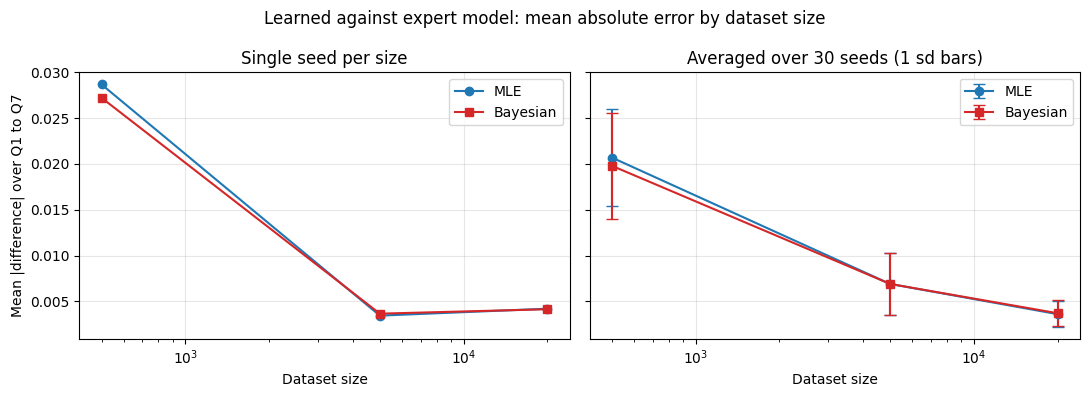

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
mad_mean = robust["mean"].unstack()
mad_std = robust["std"].unstack()
styles = {"MLE": ("o-", "#1f77b4"), "Bayesian": ("s-", "#d62728")}

for kind, (marker, colour) in styles.items():
    axes[0].plot(SIZES, mad_single[kind], marker, color=colour, label=kind)
    axes[1].errorbar(SIZES, mad_mean[kind], yerr=mad_std[kind], fmt=marker,
                     color=colour, capsize=4, label=kind)

axes[0].set_title("Single seed per size")
axes[1].set_title(f"Averaged over {REPEATS} seeds (1 sd bars)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Dataset size")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Mean |difference| over Q1 to Q7")

fig.suptitle("Learned against expert model: mean absolute error by dataset size")
fig.tight_layout()
fig.savefig("error_vs_size.png", dpi=150, bbox_inches="tight")
plt.show()

### E2. Which query is worst at n = 500, and why

In [22]:
small = tables[500]
for kind in ESTIMATORS:
    column = small[f"|Diff| {kind}"]
    print(f"largest error at n=500, {kind:8s}: {column.idxmax()} = {column.max():.4f}")

d500 = data[500]
evidence_rows = {
    "Q1": len(d500),
    "Q2": (d500.Weather == "Hot").sum(),
    "Q3": (d500.DayType == "Weekend").sum(),
    "Q4": ((d500.Weather == "Cold") & (d500.Occupancy == "High")).sum(),
    "Q5": (d500.Energy == "High").sum(),
    "Q6": (d500.Energy == "High").sum(),
    "Q7": ((d500.Energy == "High") & (d500.Load == "Heavy")).sum(),
}

print("\nRows out of 500 matching each query's evidence")
print(pd.DataFrame({"rows": pd.Series(evidence_rows),
                    "share": (pd.Series(evidence_rows) / len(d500)).round(3),
                    "|Diff| MLE": small["|Diff| MLE"]}).to_string())

largest error at n=500, MLE     : Q4 = 0.0639
largest error at n=500, Bayesian: Q4 = 0.0575

Rows out of 500 matching each query's evidence
    rows  share  |Diff| MLE
Q1   500  1.000      0.0237
Q2   255  0.510      0.0013
Q3   157  0.314      0.0310
Q4    51  0.102      0.0639
Q5   280  0.560      0.0373
Q6   280  0.560      0.0351
Q7   198  0.396      0.0085


To see which learned CPTs actually carry Q4's error, each one is restored to its
expert values in turn and Q4 recomputed.

In [23]:
def cpt_of(learned):
    """Pull a fitted model back into the plain dict form that enum_query uses."""
    out = {}
    for var in ORDER:
        cpd = learned.get_cpds(var)
        out[var] = {
            cfg: {s: cpd.get_value(**{var: s, **dict(zip(PARENTS[var], cfg))})
                  for s in STATES[var]}
            for cfg in product(*[STATES[par] for par in PARENTS[var]])}
    return out


mle_cpt = cpt_of(models[500, "MLE"])
q4 = QUERIES["Q4"]
q4_mle = enum_query(mle_cpt, *q4)

print(f"expert Q4          = {expert['Q4']:.4f}")
print(f"MLE Q4 at n=500    = {q4_mle:.4f}   (error {q4_mle - expert['Q4']:+.4f})\n")

for var in ORDER:
    hybrid = {v: (CPT[v] if v == var else mle_cpt[v]) for v in ORDER}
    value = enum_query(hybrid, *q4)
    print(f"  {var:10s} restored to expert -> Q4 = {value:.4f}"
          f"   (moves {value - q4_mle:+.4f})")

print("\nthe parameters Q4 leans on most, learned against true")
print(f"  P(Load=Heavy | O=High)   {mle_cpt['Load'][('High',)]['Heavy']:.4f}  vs 0.75")
print(f"  P(E=High | Off, Heavy)   {mle_cpt['Energy'][('Off', 'Heavy')]['High']:.4f}  vs 0.55")
print(f"  P(E=High | Off, Light)   {mle_cpt['Energy'][('Off', 'Light')]['High']:.4f}  vs 0.12")
print(f"  P(AC=On | Cold, High)    {mle_cpt['AC'][('Cold', 'High')]['On']:.4f}  vs 0.10")

expert Q4          = 0.4843
MLE Q4 at n=500    = 0.4203   (error -0.0639)

  Weather    restored to expert -> Q4 = 0.4203   (moves -0.0000)
  DayType    restored to expert -> Q4 = 0.4203   (moves +0.0000)
  Occupancy  restored to expert -> Q4 = 0.4203   (moves +0.0000)
  AC         restored to expert -> Q4 = 0.4213   (moves +0.0010)
  Load       restored to expert -> Q4 = 0.4428   (moves +0.0224)
  Energy     restored to expert -> Q4 = 0.4618   (moves +0.0415)

the parameters Q4 leans on most, learned against true
  P(Load=Heavy | O=High)   0.6975  vs 0.75
  P(E=High | Off, Heavy)   0.5071  vs 0.55
  P(E=High | Off, Light)   0.0598  vs 0.12
  P(AC=On | Cold, High)    0.0980  vs 0.10


**Q4 is the worst at n = 500**, for both estimators: 0.0639 under MLE and 0.0575
under Bayesian. It also has the thinnest evidence of the seven, matching only 51
of the 500 rows, against 255 for Q2 and 280 for Q5 and Q6.

The sensitivity run shows the error is not quite where you would expect, though.
P(AC=On | Cold, High), learned from exactly those 51 rows, came out at 0.0980
against a true 0.10, so restoring it shifts Q4 by only +0.0010. Cold weather
means the AC is nearly always off, so Q4 actually rides on the AC=Off rows of the
Energy CPT and on P(Load=Heavy | O=High), and all three were underestimated
together on this sample: 0.5071 against 0.55, 0.0598 against 0.12, and 0.6975
against 0.75. Restoring Energy recovers +0.0415 and Load a further +0.0224, which
is essentially the whole gap.

So Q4 loses twice over: it has the rarest evidence, and the three learned CPTs it
does depend on all happened to err in the same direction, so their errors compound
instead of cancelling.
Q2 is the contrast, with plenty of data behind its parameters and the smallest
error of the seven at 0.0013.

### E3. Which estimator is better on small datasets

Bayesian estimation wins at n = 500: 0.02722 against 0.02868 on the reported
seed, and 0.0198 against 0.0207 averaged over 30 seeds, so it is not one lucky
draw. MLE uses raw frequencies, so rare parent configurations give
high-variance estimates and anything unobserved is assigned probability 0, a
stronger claim than 500 rows can support. BDeu adds pseudo-counts and pulls
sparse rows toward uniform: the (Cold, Low) column had 1 of 51 days with the AC
on, so MLE reports 0.0196 against a true 0.05 while BDeu gives 0.0348. That is a
little bias for a lot less variance, which is the right trade when data is thin.
The edge then disappears as n grows, with the two level by 20000 (0.0036 against
0.0037), and the single-seed panel of the plot is a reminder that past a few
thousand rows the remaining gap is mostly about which dataset was drawn rather
than which estimator was used.